In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- airplane.jpg")
print("- input.jpg")
print("- aa.jpg")
print("- felfel-dolme.jpg")
print("- class.vision.jpg")
print("- wood-texture.jpg")
print("- iloveyouticket.jpg")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Uploaded File: {filename}")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- airplane.jpg
- input.jpg
- aa.jpg
- felfel-dolme.jpg
- class.vision.jpg
- wood-texture.jpg
- iloveyouticket.jpg


Saving aa.jpg to aa.jpg
Saving airplane.jpg to airplane.jpg
Saving class.vision.jpg to class.vision.jpg
Saving felfel-dolme.jpg to felfel-dolme.jpg
Saving iloveyouticket.jpg to iloveyouticket.jpg
Saving input.jpg to input.jpg
Saving wood-texture.jpg to wood-texture.jpg
Uploaded File: aa.jpg
Uploaded File: airplane.jpg
Uploaded File: class.vision.jpg
Uploaded File: felfel-dolme.jpg
Uploaded File: iloveyouticket.jpg
Uploaded File: input.jpg
Uploaded File: wood-texture.jpg

Contents Of Images Folder:
['wood-texture.jpg', 'input.jpg', 'class.vision.jpg', 'aa.jpg', 'iloveyouticket.jpg', 'airplane.jpg', 'felfel-dolme.jpg']


In [4]:
def combine_two_color_images(image1, image2):

  foreground, background = image1.copy(), image2.copy()

  foreground_height = foreground.shape[0]
  foreground_width = foreground.shape[1]
  alpha = 0.5

  blended_portion = cv2.addWeighted(
      foreground,
      alpha,
      background[:foreground_height, :foreground_width],
      1 - alpha,
      0,
      background
      )
  background[:foreground_height, :foreground_width] = blended_portion

  return background

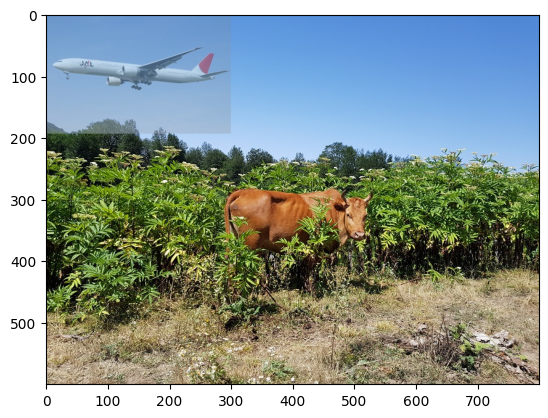

In [5]:
scr = cv2.imread("images/airplane.jpg")
dst = cv2.imread("images/input.jpg")

result = combine_two_color_images(scr, dst)

plt.imshow(result[..., ::-1])

plt.show()

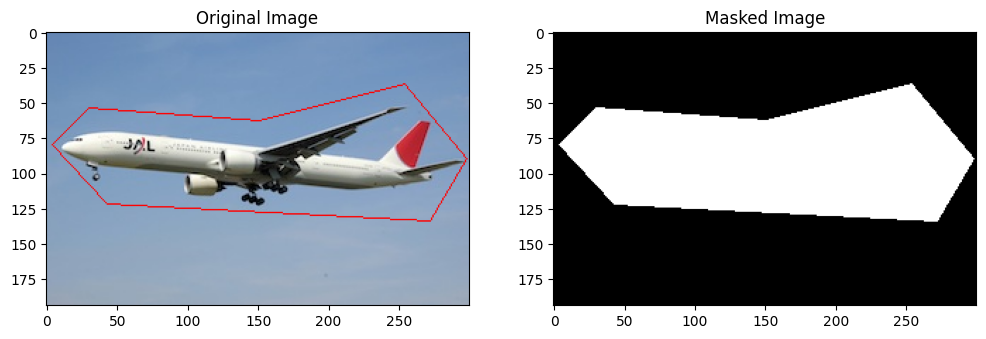

In [6]:
scr = cv2.imread("images/airplane.jpg")
poly = np.array([ [4,80], [30,54], [151,63], [254,37], [298,90], [272,134], [43,122] ], np.int32)
cv2.polylines(scr, [poly], 1, (0, 0, 255))

scr_mask = np.zeros(scr.shape, scr.dtype)
cv2.fillPoly(scr_mask, [poly], (255, 255, 255))

plt.figure(figsize=(12, 7))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(scr[..., ::-1])

plt.subplot(1, 2, 2)
plt.title("Masked Image")
plt.imshow(scr_mask[..., ::-1])

plt.show()

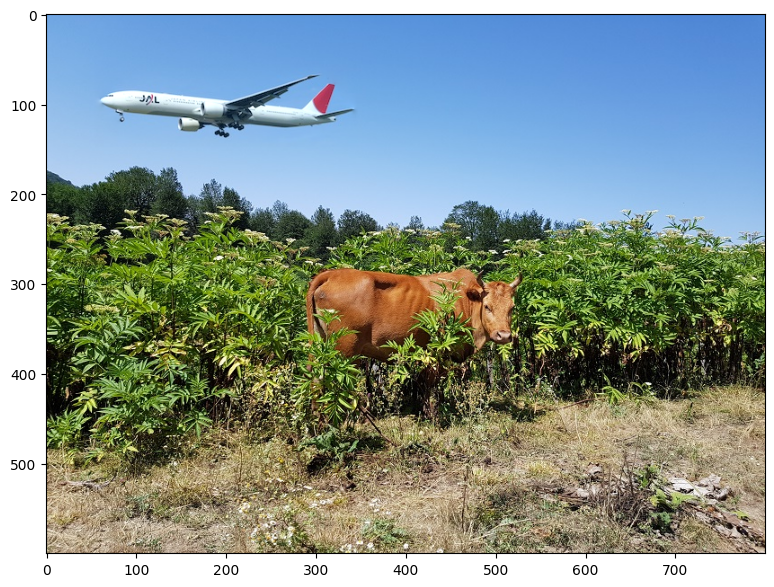

In [7]:
scr = cv2.imread("images/airplane.jpg")
dst = cv2.imread("images/input.jpg")

scr_mask = np.zeros(scr.shape, scr.dtype)
poly = np.array([ [4,80], [30,54], [151,63], [254,37], [298,90], [272,134], [43,122] ], np.int32)
cv2.fillPoly(scr_mask, [poly], (255, 255, 255))

center = (200, 100)

output = cv2.seamlessClone(scr, dst, scr_mask, center, cv2.NORMAL_CLONE)

plt.figure(figsize=(12, 7))

plt.imshow(output[..., ::-1])

plt.show()

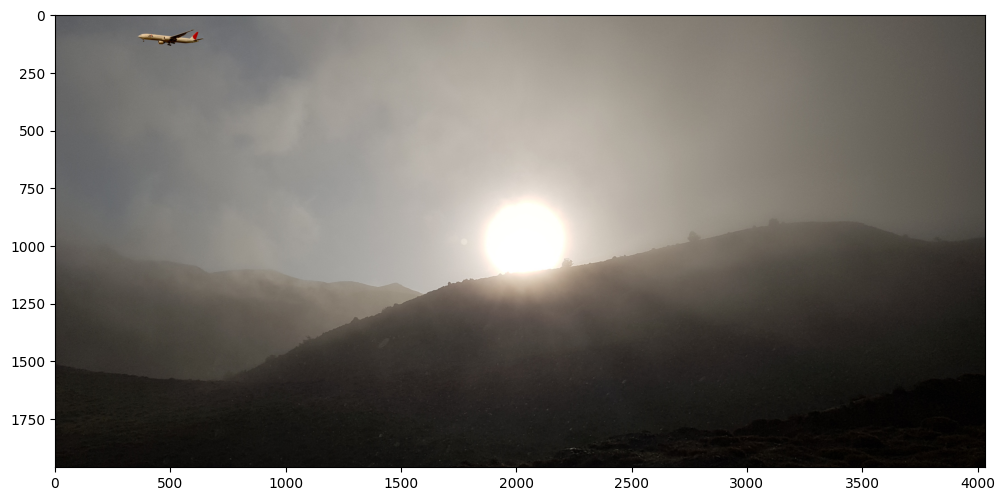

In [9]:
scr = cv2.imread("images/airplane.jpg")
dst = cv2.imread("images/aa.jpg")

scr_mask = np.zeros(scr.shape, scr.dtype)
poly = np.array([ [4,80], [30,54], [151,63], [254,37], [298,90], [272,134], [43,122] ], np.int32)
cv2.fillPoly(scr_mask, [poly], (255, 255, 255))

center = (500, 100)

output = cv2.seamlessClone(scr, dst, scr_mask, center, cv2.NORMAL_CLONE)

plt.figure(figsize=(12, 7))

plt.imshow(output[..., ::-1])

plt.show()

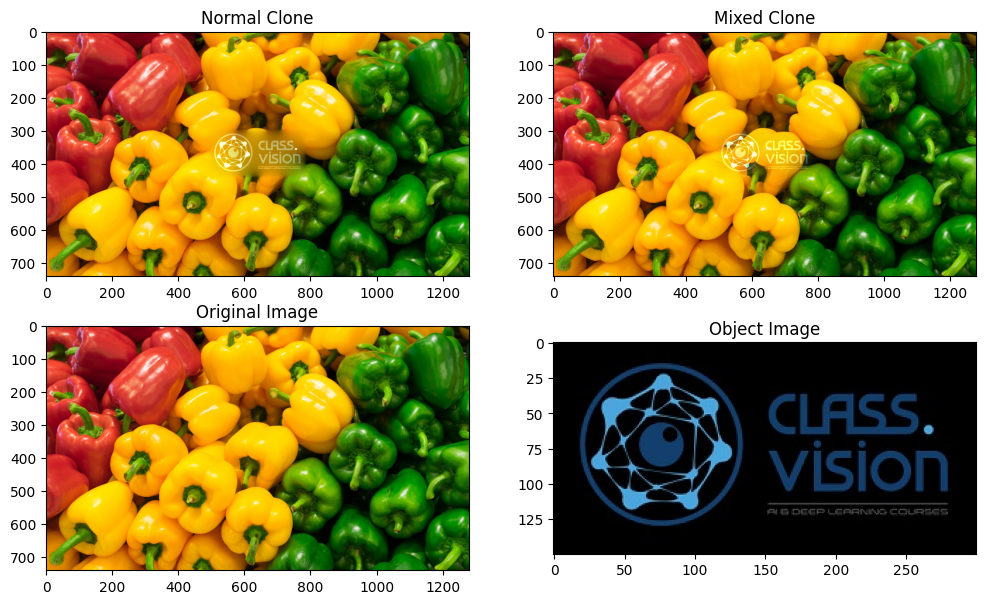

In [13]:
im = cv2.imread("images/felfel-dolme.jpg")
obj = cv2.imread("images/class.vision.jpg")

mask = 255 * np.ones(obj.shape, obj.dtype)

width, height, channel = im.shape
center = (int(height/2), int(width/2))

normal_clone = cv2.seamlessClone(obj, im, mask, center, cv2.NORMAL_CLONE)
mixed_clone = cv2.seamlessClone(obj, im, mask, center, cv2.MIXED_CLONE)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.title("Normal Clone")
plt.imshow(normal_clone[..., ::-1])

plt.subplot(2, 2, 2)
plt.title("Mixed Clone")
plt.imshow(mixed_clone[..., ::-1])

plt.subplot(2, 2, 3)
plt.title("Original Image")
plt.imshow(im[..., ::-1])

plt.subplot(2, 2, 4)
plt.title("Object Image")
plt.imshow(obj[..., ::-1])

plt.show()

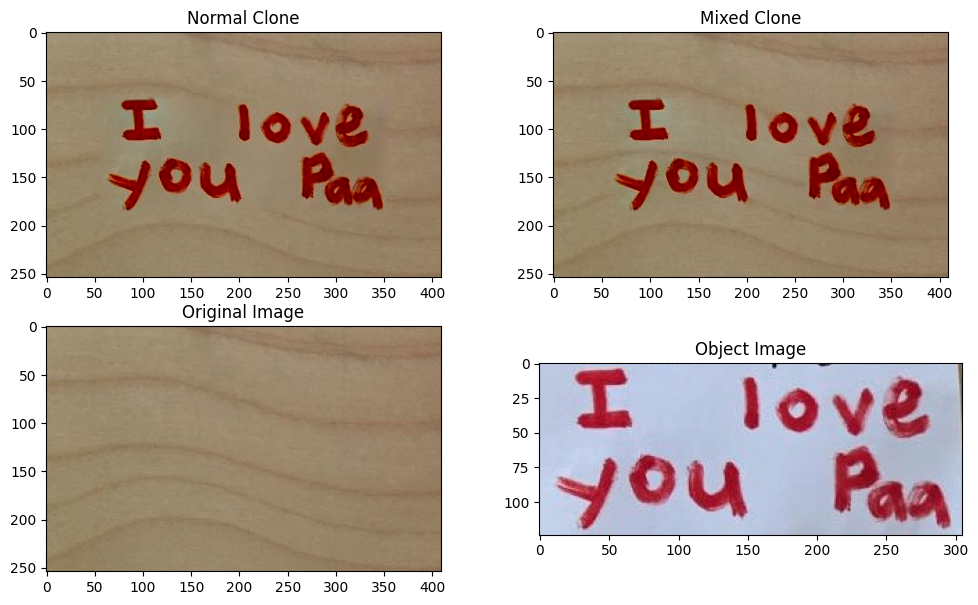

In [14]:
im = cv2.imread("images/wood-texture.jpg")
obj = cv2.imread("images/iloveyouticket.jpg")

mask = 255 * np.ones(obj.shape, obj.dtype)

width, height, channel = im.shape
center = (int(height/2), int(width/2))

normal_clone = cv2.seamlessClone(obj, im, mask, center, cv2.NORMAL_CLONE)
mixed_clone = cv2.seamlessClone(obj, im, mask, center, cv2.MIXED_CLONE)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.imshow(normal_clone[..., ::-1])
plt.title("Normal Clone")

plt.subplot(2, 2, 2)
plt.imshow(mixed_clone[..., ::-1])
plt.title("Mixed Clone")

plt.subplot(2, 2, 3)
plt.imshow(im[..., ::-1])
plt.title("Original Image")

plt.subplot(2, 2, 4)
plt.imshow(obj[..., ::-1])
plt.title("Object Image")

plt.show()